- Authors: Furkan Cantürk & Gemini 3 Pro
- Date: 21.11.2025

# Module 3: Time Series Forecasting

## 1. Problem Statement: Forecasting Bike Rentals

**The Goal:** Predict the number of bikes rented (`count`) for specific hours in the future.

**Why Time Series is Different:**
* **IID Violation:** In standard ML (like Module 1 & 2), we assume data points are Independent and Identically Distributed (IID). In Time Series, today depends heavily on yesterday.
* **Splitting:** We cannot use random `train_test_split`. We cannot predict "Last Tuesday" using data from "Next Friday". We must use **Time-based splitting**.

**Models Covered:**
1.  **Statistical (via StatsForecast):** Naive, Seasonal Naive, **AutoARIMA (SARIMAX)**.
2.  **Machine Learning:** XGBoost / LightGBM with feature engineering.
3.  **Ensemble:** Weighted average of the best models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.datasets import fetch_openml
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import xgboost as xgb
import lightgbm as lgb
import warnings

# StatsForecast imports
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoARIMA

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

c:\Users\Asus\miniconda3\envs\ml_crash_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data Loading & Visualization

We use the **Bike Sharing Demand** dataset. It is hourly data.

* **Key Columns:** `dteday` (Date), `hr` (Hour), `count` (Target - Count of bikes).
* **Exogenous:** `temp`, `hum`, `windspeed`, `season`, `holiday`.

In [2]:
print("Loading Bike Sharing dataset...")
# ID 42712 is Bike Sharing Demand (Hourly)
bikes = fetch_openml(data_id=42712, as_frame=True, parser='auto')
df = bikes.frame

# Create a proper Datetime Index
# The current dataframe does not have 'dteday' or 'hr' columns; available cols include:
# ['season','year','month','hour','holiday','weekday','workingday', ... , 'count']
# We'll construct a continuous hourly index. If you know the true start date, replace '2011-01-01'.
df['datetime'] = pd.date_range(start='2011-01-01', periods=len(df), freq='H')
df = df.set_index('datetime').sort_index()

# Drop columns we don't need for raw forecasting (we might use them for ML later)
# We focus on 'count' as the target.
target_col = 'count'

print(f"Time Series Range: {df.index.min()} to {df.index.max()}")
print(f"Total Hours: {len(df)}")

# Visualization
# Let's plot just the last 3 weeks to see the pattern clearly
last_3_weeks = df.tail(24 * 21)
fig = px.line(last_3_weeks, y=target_col, title='Hourly Bike Demand (Last 3 Weeks)')
fig.show()

Loading Bike Sharing dataset...
Time Series Range: 2011-01-01 00:00:00 to 2012-12-25 02:00:00
Total Hours: 17379


In [3]:
df.columns

Index(['season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday',
       'weather', 'temp', 'feel_temp', 'humidity', 'windspeed', 'count'],
      dtype='object')

## 3. Splitting: The "No-Peeking" Rule

We **cannot** use K-Fold Cross Validation with shuffling.
* **Bad:** Training on Jan 1st and Jan 3rd to predict Jan 2nd.
* **Good:** Training on Jan 1st and Jan 2nd to predict Jan 3rd.

We will use a simple **Cutoff Date** for this workshop, simulating a real-world scenario where we stand at a specific point in time and forecast the future.

Train Shape: (17211, 13)
Test Shape: (168, 13)


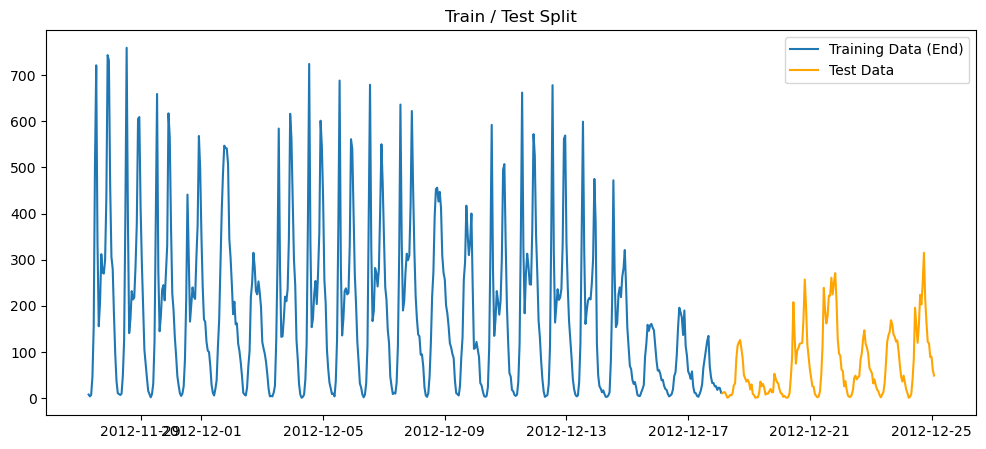

In [3]:
# Define Split Point
# Let's hold out the last 1 week (168 hours) for testing
TEST_SIZE = 168 
train = df.iloc[:-TEST_SIZE].copy()
test = df.iloc[-TEST_SIZE:].copy()

print(f"Train Shape: {train.shape}")
print(f"Test Shape: {test.shape}")

plt.figure(figsize=(12, 5))
plt.plot(train.index[-500:], train[target_col].iloc[-500:], label='Training Data (End)')
plt.plot(test.index, test[target_col], label='Test Data', color='orange')
plt.title("Train / Test Split")
plt.legend()
plt.show()

## 4. Evaluation Metric Setup

We need a consistent way to judge models.
* **MAE:** Mean Absolute Error (Interpretable: "We are off by X bikes").
* **RMSE:** Root Mean Sq Error (Penalizes huge outliers more).
* **MAPE:** Percentage Error (Good for business context, but fails if actual is 0).

In [4]:
evaluation_results = []

def evaluate(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred)
    
    print(f"--- {model_name} ---")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAPE: {mape:.2%}")
    
    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

## 5. Statistical Models using `statsforecast`

We will use the **StatsForecast** library, which is efficient and standardized.

We cover:
1.  **Naive:** Forecast = Last value.
2.  **SeasonalNaive:** Forecast = Value at T-24.
3.  **AutoARIMA:** Automatically finds the best (p,d,q) and (P,D,Q) parameters for SARIMAX.
    * **SARIMAX:** Seasonal AutoRegressive Integrated Moving Average with Exogenous variables.

*Format Requirement:* `statsforecast` expects columns named `ds` (date), `y` (target), and `unique_id`.

In [ ]:
# 1. Prepare Data for StatsForecast
train_sf = train.reset_index()[['datetime', 'count']].rename(columns={'datetime': 'ds', 'count': 'y'})
train_sf['unique_id'] = '1' # Single time series

# 2. Define Models
# season_length=24 because we have hourly data
models = [
    Naive(),
    SeasonalNaive(season_length=24), 
    # AutoARIMA hyperparameters tuned for hourly data (season_length=24)
    # - start_/max_ p/q/P/Q define search space for AR and MA orders
    # - D=1 assumes one seasonal difference; max_d/max_D limit differencing search
    # - stepwise=True speeds up search; information_criterion='aicc' prefers smaller models
    # This takes longer (5-10 mins) to train due to model search, you can reduce nmodels ~20 for faster results
    AutoARIMA(season_length=24, start_p=1, start_q=1, max_p=3, max_q=3, start_P=0, start_Q=0, max_P=2, max_Q=2, d=None, D=1, max_d=2, max_D=1, seasonal=True, nmodels=50, stepwise=True, approximation=True, ic='aicc', trace=True),
]

# 3. Instantiate StatsForecast
sf = StatsForecast(
    models=models,
    freq='H', 
    n_jobs=-1
)

print("Training Statistical Models (this may take a moment for AutoARIMA)...")
sf.fit(train_sf)

# 4. Forecast
forecast_df = sf.predict(h=len(test))
forecast_df = forecast_df.reset_index().set_index('ds')

# 5. Evaluate Statistical Models
print("\n--- Statistical Model Results ---")
y_true = test[target_col]

# Naive
y_pred_naive = forecast_df['Naive']
evaluate("StatsForecast: Naive", y_true, y_pred_naive)

# Seasonal Naive
y_pred_snaive = forecast_df['SeasonalNaive']
evaluate("StatsForecast: Seasonal Naive", y_true, y_pred_snaive)

# AutoARIMA (SARIMAX)
y_pred_arima = forecast_df['AutoARIMA']
evaluate("StatsForecast: AutoARIMA (SARIMAX)", y_true, y_pred_arima)

Training Statistical Models (this may take a moment for AutoARIMA)...
Fitting models using approximations to speed things up

ARIMA(1,0,1)(0,1,0)[24] with drift        :33256.013234594

ARIMA(0,0,0)(0,1,0)[24] with drift        :48552.76200902058

ARIMA(1,0,0)(1,1,0)[24] with drift        :34677.680013612386

ARIMA(0,0,1)(0,1,1)[24] with drift        :inf

ARIMA(0,0,0)(0,1,0)[24]                   :48550.76154369136

ARIMA(1,0,1)(1,1,0)[24] with drift        :32564.816030547907

ARIMA(1,0,1)(2,1,0)[24] with drift        :31498.173243785342

ARIMA(1,0,1)(2,1,1)[24] with drift        :inf

ARIMA(1,0,1)(1,1,1)[24] with drift        :inf

ARIMA(0,0,1)(2,1,0)[24] with drift        :35477.75549888443

ARIMA(1,0,0)(2,1,0)[24] with drift        :33452.17696524604

ARIMA(2,0,1)(2,1,0)[24] with drift        :31319.46370967987

ARIMA(2,0,1)(1,1,0)[24] with drift        :32363.9159922232

ARIMA(2,0,1)(2,1,1)[24] with drift        :inf

ARIMA(2,0,1)(1,1,1)[24] with drift        :inf

ARIMA(2,0,0)(2

## 6. Machine Learning Approach (XGBoost / LightGBM)

Standard ML models (XGBoost) assume rows are independent. They don't know that "row 50" comes after "row 49".

**Feature Engineering is King:** We must *teach* the model about time by creating features.

1.  **Calendar Features:** Hour, DayOfWeek, Month, IsWeekend.
2.  **Lag Features:** "What was the value 24 hours ago?"

*Strategy for Workshop:* We will use the **Calendar Features** + **Exogenous Variables** (Weather).

In [6]:
def create_features(df_in, target_col='count'):
    df_out = df_in.copy()
    # Calendar features
    df_out['hour'] = df_out.index.hour
    df_out['dayofweek'] = df_out.index.dayofweek
    df_out['quarter'] = df_out.index.quarter
    df_out['month'] = df_out.index.month
    df_out['year'] = df_out.index.year
    df_out['dayofyear'] = df_out.index.dayofyear
    # Lag features: 1-hour, 24-hour (daily), 168-hour (weekly)
    for lag in [1, 24, 168]:
        df_out[f'lag_{lag}'] = df_out[target_col].shift(lag)
    # Rolling statistics (previous day window)
    df_out['rolling_mean_24'] = df_out[target_col].shift(1).rolling(window=24, min_periods=1).mean()
    df_out['rolling_std_24'] = df_out[target_col].shift(1).rolling(window=24, min_periods=1).std().fillna(0)
    return df_out

# Build features on the full dataframe so lags cross the train/test boundary
df_feat = create_features(df, target_col=target_col)
# Drop initial rows with NaNs introduced by lagging
df_feat = df_feat.dropna()

# Define split (last TEST_SIZE hours as test). If TEST_SIZE exists earlier it will be overwritten here to be explicit.
TEST_SIZE = 168
train = df_feat.iloc[:-TEST_SIZE].copy()
test = df_feat.iloc[-TEST_SIZE:].copy()

print(f"Train Shape: {train.shape}")
print(f"Test Shape: {test.shape}")

# Select features for modeling (includes lag + rolling stats + calendar + exogenous vars)
features = ['hour', 'dayofweek', 'quarter', 'month', 'temp', 'feel_temp', 'humidity', 'windspeed', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_std_24']
X_train_feats = train[features]
X_test_feats = test[features]
y_train = train[target_col]
y_test = test[target_col]

# --- XGBoost (Time-series with lag features) using xgb.train ---
dtrain = xgb.DMatrix(X_train_feats, label=y_train)
dtest = xgb.DMatrix(X_test_feats, label=y_test)
params = {'objective': 'reg:squarederror', 'learning_rate': 0.05, 'max_depth': 5}
evals = [(dtrain, 'train'), (dtest, 'eval')]
evals_result = {}
xgb_model = xgb.train(params, dtrain, num_boost_round=1000, evals=evals, early_stopping_rounds=50, evals_result=evals_result, verbose_eval=False)

xgb_pred = xgb_model.predict(dtest)
evaluate("XGBoost (TimeSeries w/ lags)", y_test, xgb_pred)

# --- LightGBM (Time-series with lag features) ---
lgbm = lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=-1)
lgbm.fit(X_train_feats, y_train, eval_set=[(X_test_feats, y_test)], callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=0)])

lgbm_pred = lgbm.predict(X_test_feats)
evaluate("LightGBM (TimeSeries w/ lags)", y_test, lgbm_pred)

Train Shape: (17043, 21)
Test Shape: (168, 21)
--- XGBoost (TimeSeries w/ lags) ---
MAE: 26.01
RMSE: 39.29
MAPE: 81.38%
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001002 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1549
[LightGBM] [Info] Number of data points in the train set: 17043, number of used features: 13
[LightGBM] [Info] Start training from score 191.906002
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[63]	valid_0's l2: 1566.01
--- LightGBM (TimeSeries w/ lags) ---
MAE: 28.53
RMSE: 39.57
MAPE: 156.58%


## 7. Weighted Average Ensembling

Let's combine the best statistical model (SARIMAX) with the best ML model (XGBoost).

* **Statistical models** are good at repeating standard seasonal patterns.
* **ML models** are good at handling external variables (like Temperature or Wind).

In [7]:
# Feature Importance Comparison (Interactive with Plotly)

# Extract feature importance from XGBoost
xgb_importance = xgb_model.get_score(importance_type='weight')
xgb_features = list(xgb_importance.keys())
xgb_scores = list(xgb_importance.values())

# Extract feature importance from LightGBM
lgbm_importance = lgbm.feature_importances_
lgbm_features = features

# Create a DataFrame for XGBoost importance
xgb_imp_df = pd.DataFrame({
    'Feature': xgb_features,
    'Importance': xgb_scores,
    'Model': 'XGBoost'
}).sort_values('Importance', ascending=False).head(10)

# Create a DataFrame for LightGBM importance
lgbm_imp_df = pd.DataFrame({
    'Feature': lgbm_features,
    'Importance': lgbm_importance,
    'Model': 'LightGBM'
}).sort_values('Importance', ascending=False).head(10)

# Combine both DataFrames
combined_imp_df = pd.concat([xgb_imp_df, lgbm_imp_df], ignore_index=True)

# Plot XGBoost Feature Importance with Plotly
fig_xgb = px.bar(xgb_imp_df, x='Importance', y='Feature', orientation='h',
                   title='XGBoost: Top 10 Feature Importance',
                   color='Importance', color_continuous_scale='blues',
                   labels={'Importance': 'Feature Importance (Weight)', 'Feature': 'Feature'})
fig_xgb.update_layout(yaxis={'categoryorder': 'total ascending'}, height=500)
fig_xgb.show()

# Plot LightGBM Feature Importance with Plotly
fig_lgbm = px.bar(lgbm_imp_df, x='Importance', y='Feature', orientation='h',
                    title='LightGBM: Top 10 Feature Importance',
                    color='Importance', color_continuous_scale='oranges',
                    labels={'Importance': 'Feature Importance (Gain)', 'Feature': 'Feature'})
fig_lgbm.update_layout(yaxis={'categoryorder': 'total ascending'}, height=500)
fig_lgbm.show()

# Combined comparison (side-by-side)
fig_combined = px.bar(combined_imp_df, x='Importance', y='Feature', orientation='h',
                       color='Model', title='Feature Importance: XGBoost vs LightGBM',
                       barmode='group', color_discrete_map={'XGBoost': 'steelblue', 'LightGBM': 'darkorange'},
                       labels={'Importance': 'Importance Score', 'Feature': 'Feature'})
fig_combined.update_layout(height=600)
fig_combined.show()

print("\n--- XGBoost Top 10 Features ---")
print(xgb_imp_df[['Feature', 'Importance']].reset_index(drop=True))
print("\n--- LightGBM Top 10 Features ---")
print(lgbm_imp_df[['Feature', 'Importance']].reset_index(drop=True))


--- XGBoost Top 10 Features ---
           Feature  Importance
0            lag_1       732.0
1           lag_24       624.0
2          lag_168       590.0
3             hour       482.0
4        dayofweek       315.0
5         humidity       263.0
6  rolling_mean_24       240.0
7   rolling_std_24       235.0
8             temp       204.0
9        feel_temp       151.0

--- LightGBM Top 10 Features ---
           Feature  Importance
0            lag_1         375
1           lag_24         356
2          lag_168         260
3             hour         205
4        dayofweek         185
5         humidity         138
6             temp          89
7  rolling_mean_24          81
8   rolling_std_24          81
9            month          45


In [8]:
# Assuming AutoARIMA and XGBoost are the contenders
ensemble_pred = (0.5 * xgb_pred) + (0.5 * y_pred_arima.values)
evaluate("Ensemble (XGB + AutoARIMA)", y_test, ensemble_pred)

--- Ensemble (XGB + AutoARIMA) ---
MAE: 28.35
RMSE: 42.70
MAPE: 138.38%


## 8. Final Evaluation & Visualization

Let's compare the actual values against our models.

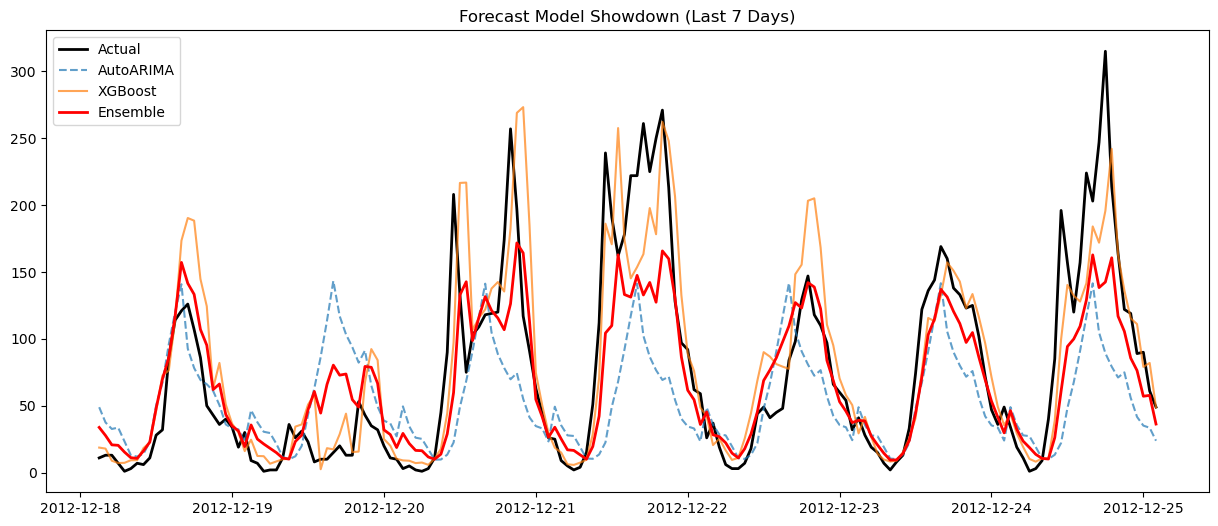


--- FINAL LEADERBOARD ---
                                Model        MAE       RMSE      MAPE
3        XGBoost (TimeSeries w/ lags)  26.005386  39.290923  0.813791
5          Ensemble (XGB + AutoARIMA)  28.348394  42.699649  1.383809
4       LightGBM (TimeSeries w/ lags)  28.526104  39.572814  1.565771
2  StatsForecast: AutoARIMA (SARIMAX)  44.837326  64.522646  2.115789
1       StatsForecast: Seasonal Naive  50.547619  74.796312  1.308824
0                StatsForecast: Naive  65.452377  95.798398  1.176591


In [9]:
# Create a comparison DataFrame
df_compare = test.copy()
df_compare['Actual'] = y_test
df_compare['XGBoost'] = xgb_pred
df_compare['AutoARIMA'] = y_pred_arima.values
df_compare['Ensemble'] = ensemble_pred

# Plot
plt.figure(figsize=(15, 6))
plt.plot(df_compare.index, df_compare['Actual'], label='Actual', color='black', linewidth=2)
plt.plot(df_compare.index, df_compare['AutoARIMA'], label='AutoARIMA', linestyle='--', alpha=0.7)
plt.plot(df_compare.index, df_compare['XGBoost'], label='XGBoost', alpha=0.7)
plt.plot(df_compare.index, df_compare['Ensemble'], label='Ensemble', color='red', linewidth=2)

plt.title("Forecast Model Showdown (Last 7 Days)")
plt.legend()
plt.show()

# Print Leaderboard
results_df = pd.DataFrame(evaluation_results).sort_values(by="MAE")
print("\n--- FINAL LEADERBOARD ---")
print(results_df)